# CSE 438

## Group Members

| Name | Student ID |
|------|------------|
| Sumiaya Sharif | 2023-1-60-048 |
| Ohiduzzaman Rayhan | 2023-1-60-108 |
| Prottoy Modak | 2022-3-60-130 |
| Afrina Alam Lamia | 2022-1-60-231 |

---

## Dataset

**Dataset Name:** FoodBD (FoodBD: A Polygon-Annotated Meal Image Dataset)

---

## Notebook

**NB0 — EDA & Data Preparation**

https://www.kaggle.com/code/sumiayasharif/nb0-eda-data-prep/edit/run/330790858

In [1]:
import os, glob, random, yaml, cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter, defaultdict
import hashlib

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_ROOT = Path("/kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD")  # <-- update to your actual dataset path
with open(DATA_ROOT / "data.yaml") as f:
    data_cfg = yaml.safe_load(f)

CLASS_NAMES = data_cfg['names']            # dict or list, id -> name
NUM_CLASSES = len(CLASS_NAMES)             # 67 foreground-labelled ids (0..66) per your yaml
print(f"Classes: {NUM_CLASSES}")
print(data_cfg)

SPLITS = {
    'train': DATA_ROOT / 'train',
    'valid': DATA_ROOT / 'valid',
    'test':  DATA_ROOT / 'test',
}

for name, p in SPLITS.items():
    imgs = sorted((p / 'images').glob('*'))
    lbls = sorted((p / 'labels').glob('*'))
    print(f"{name}: {len(imgs)} images, {len(lbls)} label files")

Classes: 67
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 67, 'names': ['achar', 'apple', 'badam', 'banana', 'beef', 'begun-vaji', 'beguni', 'biriyani', 'bread', 'burinda', 'cabbage', 'carrot', 'cauliflower', 'cha', 'chichinga-vaji', 'chicken', 'chola', 'chomchom', 'chop-alu', 'cucumber', 'daal', 'dates', 'dundol', 'egg', 'egg-boiled', 'egg-poached', 'fish', 'grapes', 'green-pea', 'guava', 'jilapi', 'juice', 'kabab', 'khichuri', 'kochu', 'korola-vaji', 'kumra-vaji', 'lal-shak', 'lau', 'lemon', 'mango', 'milk', 'noodles', 'okra', 'orange', 'papaya', 'payesh', 'peyaju', 'pineapple', 'piyaju', 'potato', 'potato-mashed', 'potol', 'puffed-rice', 'puri', 'rice', 'roll', 'ruti', 'salad', 'shak', 'shim', 'sweets', 'tomato', 'vaji', 'vegetable', 'vorta', 'watermelon']}
train: 2473 images, 2473 label files
valid: 697 images, 697 label files
test: 353 images, 353 label files


 Polygon → Mask rasterization utility

In [2]:
def polygons_to_mask(label_path, img_h, img_w, bg_is_zero=True):
    """
    Rasterize a YOLO-seg label file into a single-channel class-index mask.
    bg_is_zero=True  -> mask pixel values are (yolo_class_id + 1), 0 = background
    bg_is_zero=False -> mask pixel values are yolo_class_id directly (no explicit bg class)
    """
    mask = np.zeros((img_h, img_w), dtype=np.uint8)
    if not os.path.exists(label_path):
        return mask
    with open(label_path) as f:
        lines = [l.strip() for l in f if l.strip()]
    for line in lines:
        parts = line.split()
        cls_id = int(parts[0])
        coords = np.array(parts[1:], dtype=np.float32).reshape(-1, 2)
        coords[:, 0] *= img_w
        coords[:, 1] *= img_h
        poly = coords.astype(np.int32)
        fill_val = cls_id + 1 if bg_is_zero else cls_id
        cv2.fillPoly(mask, [poly], color=int(fill_val))
    return mask

def get_pairs(split_dir):
    img_dir, lbl_dir = split_dir / 'images', split_dir / 'labels'
    pairs = []
    for img_path in sorted(img_dir.glob('*')):
        lbl_path = lbl_dir / (img_path.stem + '.txt')
        pairs.append((img_path, lbl_path))
    return pairs

train_pairs = get_pairs(SPLITS['train'])
valid_pairs = get_pairs(SPLITS['valid'])
test_pairs  = get_pairs(SPLITS['test'])
print(len(train_pairs), len(valid_pairs), len(test_pairs))

2473 697 353


Task A: Pixel-level class distribution (full dataset)

In [3]:
def compute_pixel_class_counts(pairs, sample_size=None):
    counter = Counter()
    subset = pairs if sample_size is None else random.sample(pairs, min(sample_size, len(pairs)))
    for img_path, lbl_path in subset:
        img = cv2.imread(str(img_path))
        h, w = img.shape[:2]
        mask = polygons_to_mask(lbl_path, h, w, bg_is_zero=True)
        counter.update(Counter(mask.flatten().tolist()))
    return counter

# Full pass across all splits combined (or run per-split if you want train-only stats)
all_pairs = train_pairs + valid_pairs + test_pairs
pixel_counts = compute_pixel_class_counts(all_pairs)   # remove sample_size cap; run once, cache result

total_pixels = sum(pixel_counts.values())
rows = []
for cid in range(0, NUM_CLASSES + 1):  # 0..67 (0=background, 1..67 map to yolo ids 0..66)
    name = 'background' if cid == 0 else CLASS_NAMES[cid - 1]
    cnt = pixel_counts.get(cid, 0)
    rows.append({'class_id': cid, 'class_name': name, 'pixel_count': cnt,
                 'pct': 100 * cnt / total_pixels})

df_dist = pd.DataFrame(rows).sort_values('pct', ascending=False)
df_dist.to_csv('pixel_class_distribution.csv', index=False)
df_dist.head(15)

,class_id,class_name,pixel_count,pct
0,0,background,2620022567,70.923878
56,56,rice,304650413,8.246871
58,58,ruti,154048264,4.170079
26,26,egg-poached,63875584,1.729109
9,9,bread,51885111,1.404527
65,65,vegetable,43615565,1.180671
16,16,chicken,38435634,1.040451
21,21,daal,36137131,0.978230
27,27,fish,32051896,0.867643
20,20,cucumber,28039263,0.759021


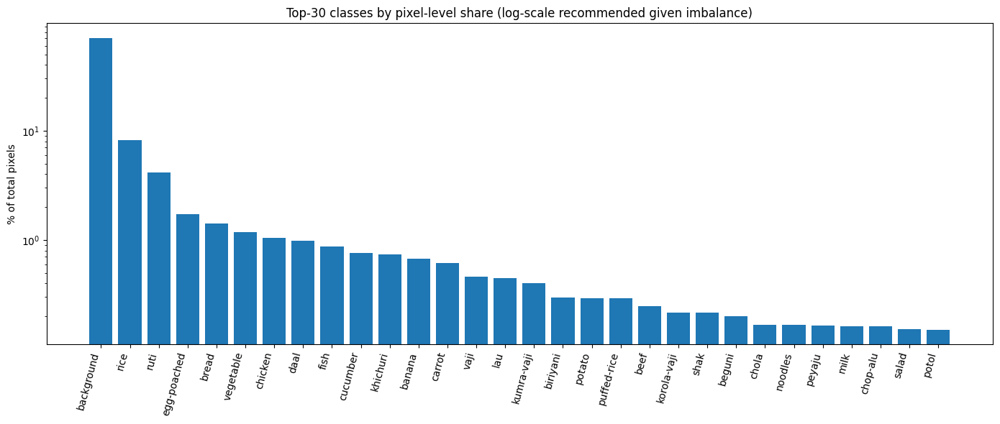

In [4]:
plt.figure(figsize=(14,6))
plt.bar(df_dist['class_name'][:30], df_dist['pct'][:30])
plt.xticks(rotation=75, ha='right')
plt.ylabel('% of total pixels')
plt.title('Top-30 classes by pixel-level share (log-scale recommended given imbalance)')
plt.yscale('log')
plt.tight_layout()
plt.savefig('pixel_class_distribution.png', dpi=150)
plt.show()

 Image size / aspect-ratio distribution

In [5]:
sizes = []
for img_path, _ in random.sample(all_pairs, min(500, len(all_pairs))):
    img = cv2.imread(str(img_path))
    sizes.append(img.shape[:2])  # (h, w)

sizes = np.array(sizes)
unique_sizes = np.unique(sizes, axis=0)
print("Unique resolutions found:", unique_sizes)
print("Uniform across dataset:", len(unique_sizes) == 1)
# Aspect ratio is trivially 1.0 for all images since resolution is fixed at 1024x1024 — no meaningful distribution to plot.

Unique resolutions found: [[1024 1024]]
Uniform across dataset: True


Representative image–mask pairs for every class

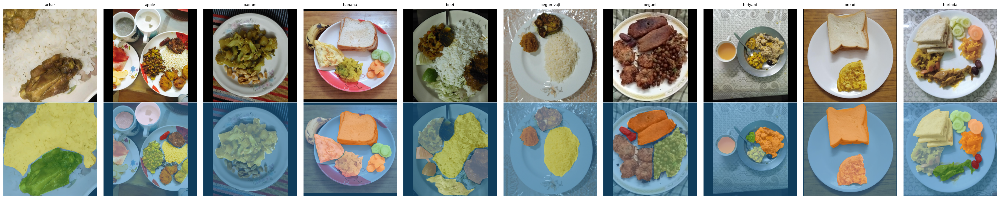

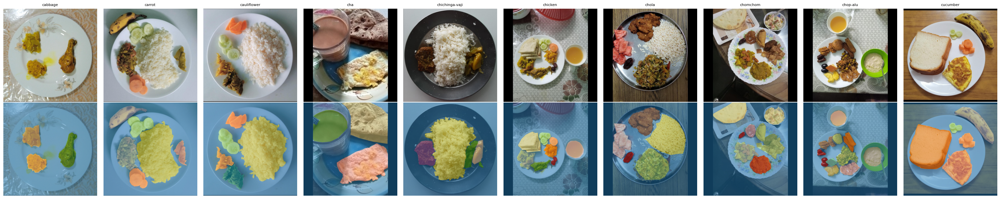

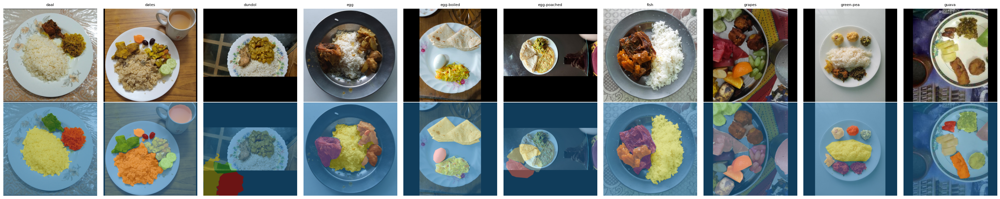

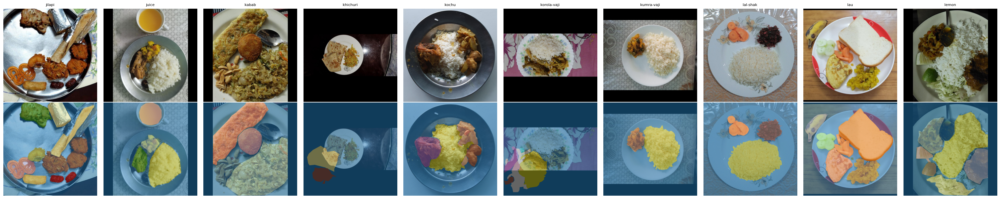

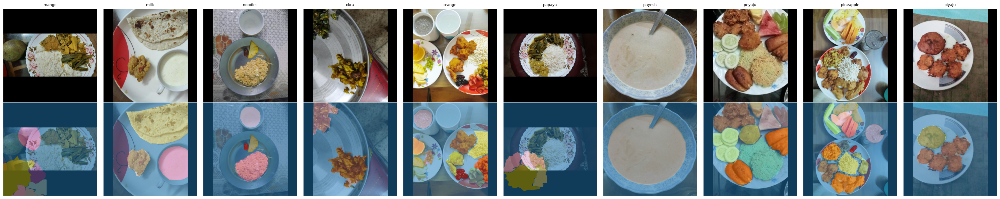

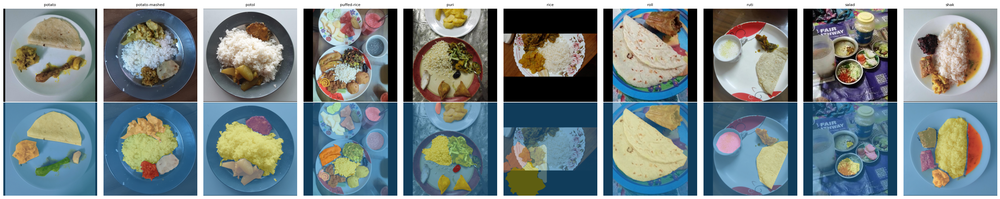

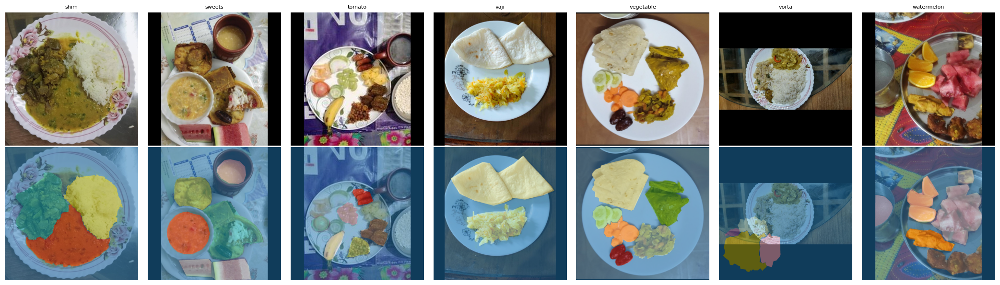

In [6]:
def find_example_for_class(target_yolo_id, pairs, max_search=800):
    for img_path, lbl_path in random.sample(pairs, min(max_search, len(pairs))):
        if not os.path.exists(lbl_path):
            continue
        with open(lbl_path) as f:
            ids = {int(l.split()[0]) for l in f if l.strip()}
        if target_yolo_id in ids:
            return img_path, lbl_path
    return None, None

def overlay_mask(img, mask, alpha=0.5, num_classes=NUM_CLASSES+1):
    cmap = plt.get_cmap('tab20', num_classes)
    color_mask = (cmap(mask)[:, :, :3] * 255).astype(np.uint8)
    return cv2.addWeighted(img, 1-alpha, color_mask, alpha, 0)

# Grid: one representative sample per class (67 classes -> paginate, e.g. 10 per figure)
classes_to_show = list(range(NUM_CLASSES))  # yolo ids 0..66
for page_start in range(0, len(classes_to_show), 10):
    page = classes_to_show[page_start:page_start+10]
    fig, axes = plt.subplots(2, len(page), figsize=(3*len(page), 6))
    for i, cid in enumerate(page):
        img_path, lbl_path = find_example_for_class(cid, train_pairs)
        if img_path is None:
            axes[0,i].axis('off'); axes[1,i].axis('off'); continue
        img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        mask = polygons_to_mask(lbl_path, h, w)
        axes[0,i].imshow(img); axes[0,i].set_title(CLASS_NAMES[cid], fontsize=8); axes[0,i].axis('off')
        axes[1,i].imshow(overlay_mask(img.copy(), mask)); axes[1,i].axis('off')
    plt.tight_layout()
    plt.show()

Near-duplicates, corrupted files, mismatched pairs

In [7]:
# Corrupted / unreadable images
corrupted = []
for img_path, _ in all_pairs:
    img = cv2.imread(str(img_path))
    if img is None:
        corrupted.append(str(img_path))
print(f"Corrupted images: {len(corrupted)}")

# Mismatched image<->label pairs (label file missing or empty when it shouldn't be)
missing_labels = [str(l) for _, l in all_pairs if not os.path.exists(l)]
print(f"Images without label files: {len(missing_labels)}")

# Near-duplicate detection via perceptual hash (cheap average-hash)
def ahash(img_path, hash_size=8):
    img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (hash_size, hash_size))
    avg = img.mean()
    bits = (img > avg).flatten()
    return hashlib.md5(bits.tobytes()).hexdigest()

hash_map = defaultdict(list)
for img_path, _ in all_pairs:
    h = ahash(img_path)
    hash_map[h].append(str(img_path))

dupes = {h: paths for h, paths in hash_map.items() if len(paths) > 1}
print(f"Near-duplicate groups found (exact ahash match): {len(dupes)}")
for h, paths in list(dupes.items())[:5]:
    print(paths)

Corrupted images: 0
Images without label files: 0
Near-duplicate groups found (exact ahash match): 26
['/kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD/train/images/FoodBD-0003.jpg', '/kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD/train/images/FoodBD-8003.jpg']
['/kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD/train/images/FoodBD-0222.jpg', '/kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD/train/images/FoodBD-8222.jpg']
['/kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD/train/images/FoodBD-0297.jpg', '/kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD/train/images/FoodBD-0298.jpg']
['/kaggle/input/datasets/sumiayasharif/foodbd/FoodBD A Polygo

Imbalance summary 
top5 = df_dist.head(6)  # includes background
print("Class imbalance summary:")
print(top5[['class_name','pct']].to_string(index=False))
print(f"\nBackground alone covers {df_dist[df_dist.class_id==0]['pct'].values[0]:.2f}% of all pixels.")
print(f"Most food classes individually cover <2% of pixels — severe long-tailed imbalance.")
print("This will drive: (1) use of weighted CE or Focal/Dice-combo loss in Task E, "
      "(2) excluding background from mIoU averaging or down-weighting it, "
      "(3) possible class-weighting inversely proportional to sqrt(pixel_count).")

Task B: Leakage-Safe Data Splitting

In [8]:
# Reuse the ahash() function from Block 6 to check cross-split duplication
def hash_split(pairs):
    return {ahash(img_path): str(img_path) for img_path, _ in pairs}

train_hashes = hash_split(train_pairs)
valid_hashes = hash_split(valid_pairs)
test_hashes  = hash_split(test_pairs)

leak_train_valid = set(train_hashes) & set(valid_hashes)
leak_train_test  = set(train_hashes) & set(test_hashes)
leak_valid_test  = set(valid_hashes) & set(test_hashes)

print(f"train<->valid leakage: {len(leak_train_valid)}")
print(f"train<->test leakage:  {len(leak_train_test)}")
print(f"valid<->test leakage:  {len(leak_valid_test)}")

if leak_train_valid or leak_train_test or leak_valid_test:
    print("WARNING: leakage detected — inspect and consider removing/re-grouping duplicates.")
else:
    print("No exact/near-duplicate leakage detected across splits (ahash-level check).")

train<->valid leakage: 9
train<->test leakage:  2
valid<->test leakage:  1


In [9]:
# Freeze and save the split as file-list artifacts so NB1-NB3 all load the identical split
split_manifest = {
    'train': [str(p[0]) for p in train_pairs],
    'valid': [str(p[0]) for p in valid_pairs],
    'test':  [str(p[0]) for p in test_pairs],
    'seed': SEED,
    'source': 'official_dataset_split',
}
import json
with open('split_manifest.json', 'w') as f:
    json.dump(split_manifest, f, indent=2)

print("Split sizes ->", {k: len(v) for k, v in split_manifest.items() if isinstance(v, list)})
print("Saved split_manifest.json — NB1/NB2/NB3 must load this exact file, not re-split.")

Split sizes -> {'train': 2473, 'valid': 697, 'test': 353}
Saved split_manifest.json — NB1/NB2/NB3 must load this exact file, not re-split.


Task C: Augmentation Pipeline (train split only)

In [ ]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

IMG_SIZE = 512  # downsize from 1024 for GPU memory; keep consistent across all 3 models

train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),          # food layout has no fixed left/right — safe
    A.VerticalFlip(p=0.5),            # top-down food photography — no fixed "up", safe
    A.RandomRotate90(p=0.5),          # plate orientation is arbitrary
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.15, rotate_limit=15, p=0.5,
                        border_mode=cv2.BORDER_CONSTANT, value=0, mask_value=0),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.4),
    A.HueSaturationValue(hue_shift_limit=8, sat_shift_limit=15, val_shift_limit=10, p=0.3),
    # mild hue shift only — food color is class-discriminative, so we cap this low
    A.GaussianBlur(blur_limit=(3,5), p=0.15),   # mimics slight camera focus variation
    A.CoarseDropout(max_holes=4, max_height=32, max_width=32, fill_value=0, mask_fill_value=0, p=0.2),
    # simulates partial occlusion (utensils, hands, garnish) — improves robustness
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
    ToTensorV2(),
])

val_test_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
    ToTensorV2(),
])
# val_test_transform is deterministic (resize + normalize only) — no augmentation on val/test, per Task C requirement

/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_23/2591528535.py:11: UserWarning: Argument(s) 'value, mask_value' are not valid for transform ShiftScaleRotate
  A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.15, rotate_limit=15, p=0.5,
/tmp/ipykernel_23/2591528535.py:17: UserWarning: Argument(s) 'max_holes, max_height, max_width, fill_value, mask_fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=4, max_height=32, max_width=32, fill_value=0, mask_fill_value=0, p=0.2),


In [11]:
# Justification table for the report
aug_justification = pd.DataFrame([
    {'transform':'HorizontalFlip','p':0.5,'reason':'No fixed left/right in plate composition'},
    {'transform':'VerticalFlip','p':0.5,'reason':'Top-down food photography has no fixed "up"'},
    {'transform':'RandomRotate90','p':0.5,'reason':'Arbitrary camera/plate rotation is realistic'},
    {'transform':'ShiftScaleRotate','p':0.5,'reason':'Simulates plate position/zoom/angle variance'},
    {'transform':'RandomBrightnessContrast','p':0.4,'reason':'Lighting varies across capture setups'},
    {'transform':'HueSaturationValue','p':0.3,'reason':'Mild only — hue is class-discriminative for food'},
    {'transform':'GaussianBlur','p':0.15,'reason':'Mimics camera focus/motion variance'},
    {'transform':'CoarseDropout','p':0.2,'reason':'Simulates occlusion by utensils/garnish/hands'},
])
aug_justification

,transform,p,reason
0,HorizontalFlip,0.50,No fixed left/right in plate composition
1,VerticalFlip,0.50,"Top-down food photography has no fixed ""up"""
2,RandomRotate90,0.50,Arbitrary camera/plate rotation is realistic
3,ShiftScaleRotate,0.50,Simulates plate position/zoom/angle variance
4,RandomBrightnessContrast,0.40,Lighting varies across capture setups
5,HueSaturationValue,0.30,Mild only — hue is class-discriminative for food
6,GaussianBlur,0.15,Mimics camera focus/motion variance
7,CoarseDropout,0.20,Simulates occlusion by utensils/garnish/hands


Dataset class wrapping polygon labels + augmentation

In [12]:
from torch.utils.data import Dataset
import torch

class FoodSegDataset(Dataset):
    def __init__(self, pairs, transform, img_size=IMG_SIZE):
        self.pairs = pairs
        self.transform = transform
        self.img_size = img_size

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, lbl_path = self.pairs[idx]
        img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        mask = polygons_to_mask(lbl_path, h, w, bg_is_zero=True)  # 0=bg, 1..67=classes
        augmented = self.transform(image=img, mask=mask)
        return augmented['image'], augmented['mask'].long()

train_ds = FoodSegDataset(train_pairs, train_transform)
valid_ds = FoodSegDataset(valid_pairs, val_test_transform)
test_ds  = FoodSegDataset(test_pairs, val_test_transform)
print(len(train_ds), len(valid_ds), len(test_ds))

2473 697 353


 Task D: Sanity-Check Visualization (mandatory quality gate before training)

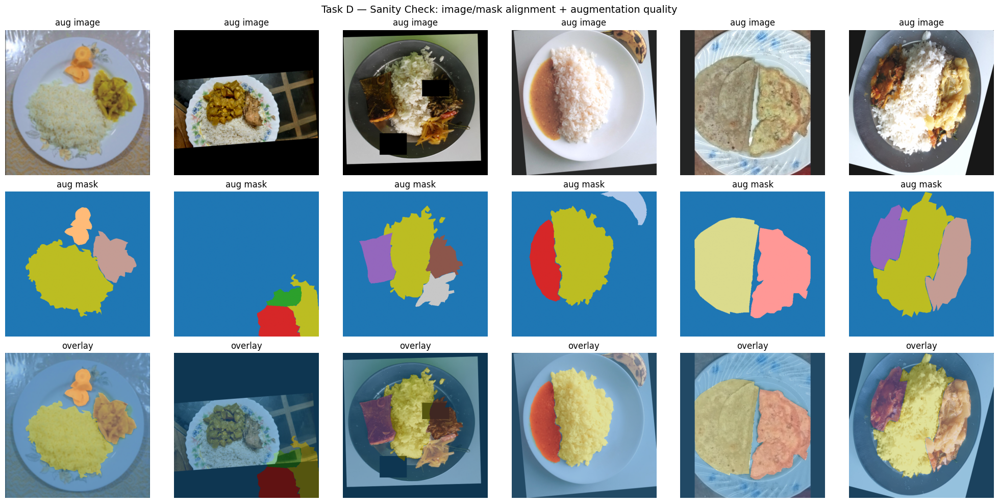

In [13]:
def denormalize(img_tensor):
    mean = np.array([0.485,0.456,0.406]).reshape(3,1,1)
    std  = np.array([0.229,0.224,0.225]).reshape(3,1,1)
    img = img_tensor.numpy() * std + mean
    img = np.clip(img.transpose(1,2,0), 0, 1)
    return img

fig, axes = plt.subplots(3, 6, figsize=(20, 10))
for i in range(6):
    img_t, mask_t = train_ds[random.randint(0, len(train_ds)-1)]
    img = denormalize(img_t)
    mask = mask_t.numpy()

    axes[0,i].imshow(img); axes[0,i].set_title('aug image'); axes[0,i].axis('off')
    axes[1,i].imshow(mask, cmap='tab20', vmin=0, vmax=NUM_CLASSES); axes[1,i].set_title('aug mask'); axes[1,i].axis('off')
    overlay = overlay_mask((img*255).astype(np.uint8), mask, alpha=0.45)
    axes[2,i].imshow(overlay); axes[2,i].set_title('overlay'); axes[2,i].axis('off')

plt.suptitle('Task D — Sanity Check: image/mask alignment + augmentation quality', fontsize=14)
plt.tight_layout()
plt.savefig('sanity_check_grid.png', dpi=150)
plt.show()

Saved everything from NB0 for reuse in NB1/NB2/NB3

In [14]:
import os, json

SAVE_DIR = "/kaggle/working/nb0_artifacts"
os.makedirs(SAVE_DIR, exist_ok=True)

with open(f"{SAVE_DIR}/split_manifest.json", "w") as f:
    json.dump(split_manifest, f, indent=2)

common_config = {
    "num_classes_fg": NUM_CLASSES,
    "num_classes_total": NUM_CLASSES + 1,
    "class_names": CLASS_NAMES,
    "img_size": IMG_SIZE,
    "seed": SEED,
    "bg_is_zero": True,
    "data_root": str(DATA_ROOT),
}
with open(f"{SAVE_DIR}/common_config.json", "w") as f:
    json.dump(common_config, f, indent=2)

df_dist.to_csv(f"{SAVE_DIR}/pixel_class_distribution.csv", index=False)

print("Saved json/csv artifacts.")

Saved json/csv artifacts.


In [15]:
%%writefile /kaggle/working/nb0_artifacts/seg_common.py
import cv2, os, random, json
import numpy as np
import torch
from torch.utils.data import Dataset
import albumentations as A
from albumentations.pytorch import ToTensorV2

def load_common_config(path="/kaggle/input/food-seg-nb0-artifacts/common_config.json"):
    with open(path) as f:
        return json.load(f)

def load_split_manifest(path="/kaggle/input/food-seg-nb0-artifacts/split_manifest.json"):
    with open(path) as f:
        return json.load(f)

def polygons_to_mask(label_path, img_h, img_w, bg_is_zero=True):
    mask = np.zeros((img_h, img_w), dtype=np.uint8)
    if not os.path.exists(label_path):
        return mask
    with open(label_path) as f:
        lines = [l.strip() for l in f if l.strip()]
    for line in lines:
        parts = line.split()
        cls_id = int(parts[0])
        coords = np.array(parts[1:], dtype=np.float32).reshape(-1, 2)
        coords[:, 0] *= img_w
        coords[:, 1] *= img_h
        poly = coords.astype(np.int32)
        fill_val = cls_id + 1 if bg_is_zero else cls_id
        cv2.fillPoly(mask, [poly], color=int(fill_val))
    return mask

def get_transforms(img_size, train=True):
    if train:
        return A.Compose([
            A.Resize(img_size, img_size),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.RandomRotate90(p=0.5),
            A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.15, rotate_limit=15, p=0.5,
                                border_mode=cv2.BORDER_CONSTANT, value=0, mask_value=0),
            A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.4),
            A.HueSaturationValue(hue_shift_limit=8, sat_shift_limit=15, val_shift_limit=10, p=0.3),
            A.GaussianBlur(blur_limit=(3,5), p=0.15),
            A.CoarseDropout(max_holes=4, max_height=32, max_width=32, fill_value=0, mask_fill_value=0, p=0.2),
            A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
            ToTensorV2(),
        ])
    else:
        return A.Compose([
            A.Resize(img_size, img_size),
            A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
            ToTensorV2(),
        ])

class FoodSegDataset(Dataset):
    # img_paths: list of image file paths; label path derived by swapping images/ -> labels/ and ext -> .txt
    def __init__(self, img_paths, transform, bg_is_zero=True):
        self.img_paths = img_paths
        self.transform = transform
        self.bg_is_zero = bg_is_zero

    def _label_path(self, img_path):
        p = str(img_path).replace("/images/", "/labels/")
        return os.path.splitext(p)[0] + ".txt"

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        lbl_path = self._label_path(img_path)
        img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        mask = polygons_to_mask(lbl_path, h, w, bg_is_zero=self.bg_is_zero)
        augmented = self.transform(image=img, mask=mask)
        return augmented["image"], augmented["mask"].long()

Writing /kaggle/working/nb0_artifacts/seg_common.py


In [16]:
with open(f"{SAVE_DIR}/seg_common.py") as f:
    print(f.read()[:300], "...")

print("\nFiles in artifacts folder:")
for fn in os.listdir(SAVE_DIR):
    print(" -", fn)

import cv2, os, random, json
import numpy as np
import torch
from torch.utils.data import Dataset
import albumentations as A
from albumentations.pytorch import ToTensorV2

def load_common_config(path="/kaggle/input/food-seg-nb0-artifacts/common_config.json"):
    with open(path) as f:
        return ...

Files in artifacts folder:
 - common_config.json
 - seg_common.py
 - split_manifest.json
 - pixel_class_distribution.csv
